# Data Cleaning

# 1. Import Libraries


In [1]:
# import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# 2. Load datasets

In [2]:
# load the data from CSV files into pandas DataFrames
calendar_df = pd.read_csv('../data/calendar.csv').copy()
customers_df = pd.read_csv('../data/customers.csv').copy()
daily_revenue_df = pd.read_csv('../data/daily_revenue.csv').copy()
employee_availability_df = pd.read_csv('../data/employee_availability.csv').copy()
employees_df = pd.read_csv('../data/employees.csv').copy()
order_items_df = pd.read_csv('../data/order_items.csv').copy()
orders_df = pd.read_csv('../data/orders.csv').copy()
payments_df = pd.read_csv('../data/payments.csv').copy()
products_df = pd.read_csv('../data/products.csv').copy()
promotions_df = pd.read_csv('../data/promotions.csv').copy()
review_aspect_labels_df = pd.read_csv('../data/review_aspect_labels.csv').copy()
reviews_df = pd.read_csv('../data/reviews.csv').copy()
shifts_df = pd.read_csv('../data/shifts.csv').copy()
weather_df = pd.read_csv('../data/weather.csv').copy()

# 3. Initial data inspection and exploration

In [3]:
daily_revenue_df

,date,revenue,orders,average_order_value,day_of_week,day_of_week_num,month,month_name,quarter,week_of_year,...,restaurant_day_type,holiday_name,is_holiday,temperature_c,temp_max_c,temp_min_c,precipitation_mm,is_rainy,weather_condition,is_promo_day
0,2024-01-01,1396.3,40,34.91,Monday,1,1,January,1,1,...,Quiet,New Year's Day,1,3.8,7.0,1.3,1.3,1,Rain,0
1,2024-01-02,2118.0,56,37.82,Tuesday,2,1,January,1,1,...,Quiet,NaN,0,1.3,3.6,-0.5,0.0,0,Cold,0
2,2024-01-03,1527.3,50,30.55,Wednesday,3,1,January,1,1,...,Quiet,NaN,0,3.4,5.3,1.9,7.0,1,Rain,0
3,2024-01-04,2532.3,67,37.80,Thursday,4,1,January,1,1,...,Medium,NaN,0,5.7,6.8,4.8,1.0,1,Rain,0
4,2024-01-05,3420.7,91,37.59,Friday,5,1,January,1,1,...,Peak,NaN,0,-0.1,1.3,-1.2,3.3,1,Rain,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
726,2025-12-27,4453.8,106,42.02,Saturday,6,12,December,4,52,...,Peak,NaN,0,3.1,5.6,1.0,0.0,0,Normal,0
727,2025-12-28,2529.4,67,37.75,Sunday,7,12,December,4,52,...,Medium,NaN,0,4.8,6.2,3.7,8.9,1,Rain,0
728,2025-12-29,1468.9,43,34.16,Monday,1,12,December,4,1,...,Quiet,NaN,0,1.9,3.8,0.3,0.0,0,Cold,0
729,2025-12-30,2040.0,56,36.43,Tuesday,2,12,December,4,1,...,Quiet,NaN,0,-0.5,1.0,-1.7,0.0,0,Cold,0


In [4]:
daily_revenue_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 22 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   date                 731 non-null    str    
 1   revenue              731 non-null    float64
 2   orders               731 non-null    int64  
 3   average_order_value  731 non-null    float64
 4   day_of_week          731 non-null    str    
 5   day_of_week_num      731 non-null    int64  
 6   month                731 non-null    int64  
 7   month_name           731 non-null    str    
 8   quarter              731 non-null    int64  
 9   week_of_year         731 non-null    int64  
 10  is_weekend           731 non-null    int64  
 11  restaurant_peak_day  731 non-null    int64  
 12  restaurant_day_type  731 non-null    str    
 13  holiday_name         22 non-null     str    
 14  is_holiday           731 non-null    int64  
 15  temperature_c        731 non-null    float64
 16  t

In [5]:
# change to datetime format
daily_revenue_df['date'] = pd.to_datetime(daily_revenue_df['date'], format='%Y-%m-%d')

In [6]:
# change is_rainy, is_promo_day and is_holiday datatypes to boolen format
daily_revenue_df['is_rainy']= daily_revenue_df['is_rainy'].astype(bool)
daily_revenue_df['is_promo_day']= daily_revenue_df['is_promo_day'].astype(bool)
daily_revenue_df['is_holiday']= daily_revenue_df['is_holiday'].astype(bool)
daily_revenue_df['is_weekend']= daily_revenue_df['is_weekend'].astype(bool)

In [7]:
# rename the temperature column
daily_revenue_df.rename(columns={'temperature_c': 'temperature_avg_c'},inplace=True)

In [8]:
# time difference
daily_revenue_df['date'].max()-daily_revenue_df['date'].min()

Timedelta('730 days 00:00:00')

In [9]:
daily_revenue_df.describe()

,date,revenue,orders,average_order_value,day_of_week_num,month,quarter,week_of_year,restaurant_peak_day,temperature_avg_c,temp_max_c,temp_min_c,precipitation_mm
count,731,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,2024-12-31 00:00:00,2861.610876,76.727770,36.696347,3.991792,6.519836,2.507524,26.395349,0.284542,10.683174,13.954583,8.009029,2.269767
min,2024-01-01 00:00:00,686.700000,21.000000,26.990000,1.000000,1.000000,1.000000,1.000000,0.000000,-7.600000,-5.400000,-9.500000,0.000000
25%,2024-07-01 12:00:00,2027.300000,58.000000,34.205000,2.000000,4.000000,2.000000,13.000000,0.000000,5.500000,7.650000,3.600000,0.000000
50%,2024-12-31 00:00:00,2517.180000,72.000000,36.420000,4.000000,7.000000,3.000000,26.000000,0.000000,10.800000,13.300000,8.500000,0.000000
75%,2025-07-01 12:00:00,3611.500000,93.000000,39.215000,6.000000,10.000000,4.000000,39.000000,1.000000,16.150000,20.500000,12.600000,2.000000
max,2025-12-31 00:00:00,6734.110000,160.000000,46.850000,7.000000,12.000000,4.000000,52.000000,1.000000,26.000000,32.000000,21.300000,44.300000
std,NaN,1143.703949,25.511556,3.594125,2.002037,3.451913,1.118162,15.076278,0.451505,6.493759,7.540460,5.789942,5.300902


In [10]:
daily_revenue_df.groupby("is_rainy")["revenue"].mean().round()

is_rainy
False    2937.0
True     2693.0
Name: revenue, dtype: float64

In [11]:
daily_revenue_df.groupby("is_promo_day")["revenue"].mean().round()

is_promo_day
False    2779.0
True     2993.0
Name: revenue, dtype: float64

In [12]:
# Total revenue by month
daily_revenue_df.groupby("month_name")["revenue"].sum().round()

month_name
April        159733.0
August       206005.0
December     182424.0
February     155119.0
January      154959.0
July         189314.0
June         177569.0
March        167384.0
May          180048.0
November     168481.0
October      180220.0
September    170582.0
Name: revenue, dtype: float64

<Axes: xlabel='month_name'>

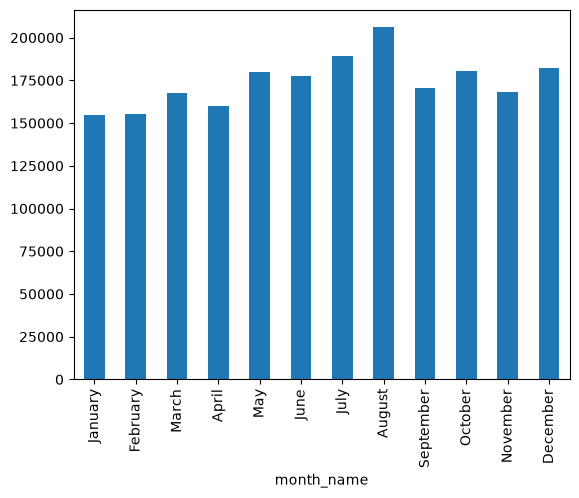

In [13]:
month = ["January", "February", "March", "April", "May", "June",
         "July", "August", "September", "October", "November", "December"]

daily_revenue_df.groupby("month_name")["revenue"].sum().round().reindex(month).plot(kind="bar")

In [14]:
# Revenue by day of week
daily_revenue_df.groupby("day_of_week")["revenue"].sum().round()

day_of_week
Friday       421812.0
Monday       183399.0
Saturday     489568.0
Sunday       273158.0
Thursday     278592.0
Tuesday      215175.0
Wednesday    230135.0
Name: revenue, dtype: float64

<Axes: xlabel='day_of_week'>

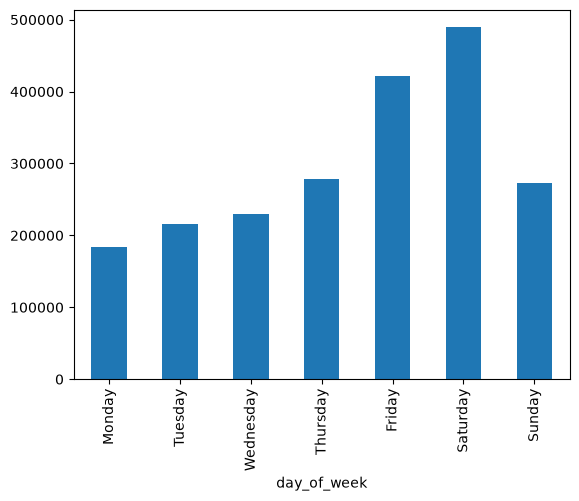

In [15]:
day = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
daily_revenue_df.groupby("day_of_week")["revenue"].sum().round().reindex(day).plot(kind="bar")

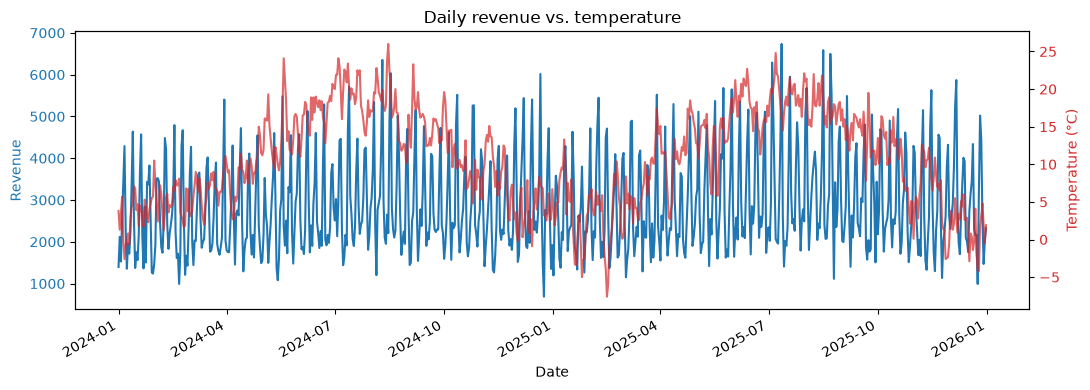

In [16]:
# daily revenue vs avg temperature
fig, ax1 = plt.subplots(figsize=(11, 4))

# Revenue on the left axis
ax1.plot(daily_revenue_df["date"], daily_revenue_df["revenue"], color="tab:blue", label="Revenue")
ax1.set_xlabel("Date")
ax1.set_ylabel("Revenue", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")

# Temperature on the right axis (shares the same x-axis)
ax2 = ax1.twinx()
ax2.plot(daily_revenue_df["date"], daily_revenue_df["temperature_avg_c"], color="tab:red", alpha=0.7, label="Temperature")
ax2.set_ylabel("Temperature (°C)", color="tab:red")
ax2.tick_params(axis="y", labelcolor="tab:red")

ax1.set_title("Daily revenue vs. temperature")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

In [17]:
daily_revenue_df[
    ["revenue", "temperature_avg_c", "precipitation_mm"]
].corr().round(3)

,revenue,temperature_avg_c,precipitation_mm
revenue,1.000,0.117,-0.106
temperature_avg_c,0.117,1.000,0.026
precipitation_mm,-0.106,0.026,1.000


In [18]:
orders_df

,order_id,customer_id,order_datetime,order_date,order_type,meal_period,order_total,party_size
0,O000001,NaN,2024-01-01 11:46:54,2024-01-01,Dine-in,Lunch,43.8,3
1,O000002,C01367,2024-01-01 12:14:15,2024-01-01,Dine-in,Lunch,34.1,2
2,O000003,NaN,2024-01-01 12:19:10,2024-01-01,Dine-in,Lunch,14.9,1
3,O000004,C01716,2024-01-01 12:20:54,2024-01-01,Takeaway,Lunch,12.9,1
4,O000005,C01866,2024-01-01 12:26:49,2024-01-01,Takeaway,Lunch,23.4,1
...,...,...,...,...,...,...,...,...
56083,O056084,NaN,2025-12-31 21:18:20,2025-12-31,Dine-in,Dinner,58.9,3
56084,O056085,C00920,2025-12-31 21:26:50,2025-12-31,Dine-in,Dinner,15.4,1
56085,O056086,C04788,2025-12-31 21:28:54,2025-12-31,Dine-in,Dinner,12.9,1
56086,O056087,NaN,2025-12-31 21:35:52,2025-12-31,Dine-in,Dinner,64.6,4


In [19]:
orders_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 56088 entries, 0 to 56087
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        56088 non-null  str    
 1   customer_id     34049 non-null  str    
 2   order_datetime  56088 non-null  str    
 3   order_date      56088 non-null  str    
 4   order_type      56088 non-null  str    
 5   meal_period     56088 non-null  str    
 6   order_total     56088 non-null  float64
 7   party_size      56088 non-null  int64  
dtypes: float64(1), int64(1), str(6)
memory usage: 6.3 MB


checking the missing values in `customer_id`

In [20]:
# 1. Orders
print("Orders without customer ID:",
      orders_df["customer_id"].isna().sum())

print("Percentage:",
      orders_df["customer_id"].isna().mean() * 100)

# 2. Reviews
print("Reviews without customer ID:",
      reviews_df["customer_id"].isna().sum())

print("Percentage:",
      reviews_df["customer_id"].isna().mean() * 100)

# 3. Customer IDs referenced by reviews
print(
    "Invalid customer references:",
    (
        ~reviews_df["customer_id"].dropna()
        .isin(customers_df["customer_id"])
    ).sum()
)


Orders without customer ID: 22039
Percentage: 39.29361004136357
Reviews without customer ID: 0
Percentage: 0.0
Invalid customer references: 0


In [21]:
# 4. Missing customer ID by order type
pd.crosstab(
    orders_df["order_type"],
    orders_df["customer_id"].isna(),
    normalize="index"
).round(3) * 100

customer_id,False,True
order_type,,
Delivery,95.2,4.8
Dine-in,45.4,54.6
Takeaway,70.2,29.8


### Customer ID Missingness

Approximately 39.3% of orders do not have a `customer_id`. These orders are retained because they are still valid transactions and are required for complete revenue and demand analysis.
```
- Delivery: 4.8% missing customer IDs
- Dine-in: 54.6% missing customer IDs
- Takeaway: 29.8% missing customer IDs
```
The pattern is consistent with anonymous restaurant transactions, particularly dine-in orders. These orders remain valid for revenue and demand analysis because they contain transaction-level information.

No customer IDs are missing from the reviews table, and no invalid customer references were found. Therefore, customer-level review and sentiment analysis can be performed without imputing customer IDs.

Missing customer IDs are therefore retained as valid anonymous transactions.removed.

In [22]:
# change to datetime format
orders_df["order_datetime"] = pd.to_datetime(orders_df["order_datetime"])
orders_df["order_date"] = pd.to_datetime(orders_df["order_date"])

In [23]:
orders_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 56088 entries, 0 to 56087
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        56088 non-null  str           
 1   customer_id     34049 non-null  str           
 2   order_datetime  56088 non-null  datetime64[us]
 3   order_date      56088 non-null  datetime64[us]
 4   order_type      56088 non-null  str           
 5   meal_period     56088 non-null  str           
 6   order_total     56088 non-null  float64       
 7   party_size      56088 non-null  int64         
dtypes: datetime64[us](2), float64(1), int64(1), str(4)
memory usage: 4.7 MB


In [24]:
orders_df.groupby("party_size")["order_total"].sum()

party_size
1    337853.85
2    757178.38
3    304162.22
4    409175.63
5    187723.31
6     95744.16
Name: order_total, dtype: float64

In [25]:
orders_df.groupby("order_type")["order_total"].sum()

order_type
Delivery     389927.22
Dine-in     1543060.67
Takeaway     158849.66
Name: order_total, dtype: float64

<Axes: xlabel='order_type'>

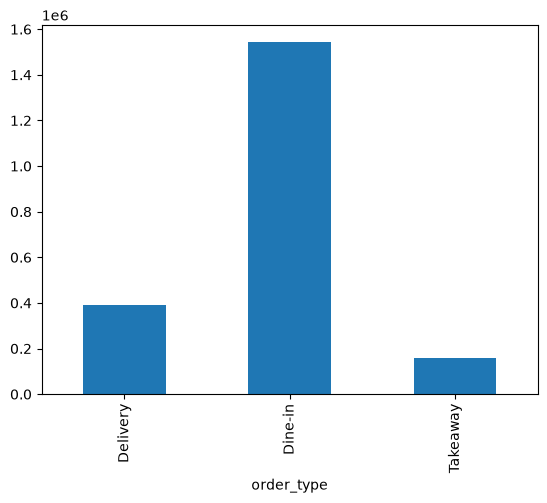

In [26]:
orders_df.groupby("order_type")["order_total"].sum().plot(kind='bar')

<Axes: xlabel='order_type'>

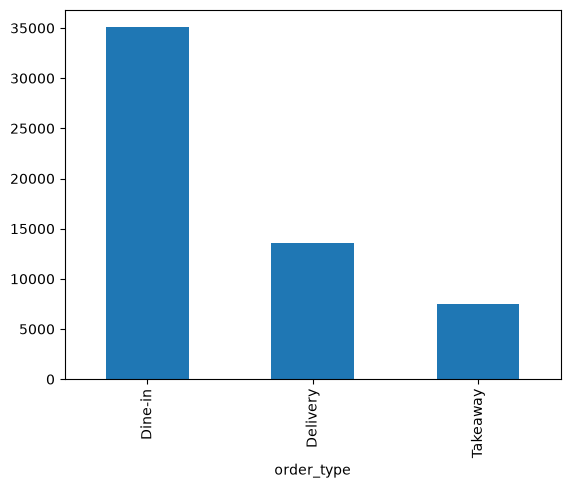

In [27]:
orders_df['order_type'].value_counts().plot(kind='bar')

In [28]:
orders_df.describe()

,order_datetime,order_date,order_total,party_size
count,56088,56088,56088.000000,56088.000000
mean,2025-01-10 09:36:33.900032,2025-01-09 16:08:16.020539,37.295635,2.130491
min,2024-01-01 11:46:54,2024-01-01 00:00:00,4.680000,1.000000
25%,2024-07-14 19:55:02,2024-07-14 00:00:00,18.800000,1.000000
50%,2025-01-12 18:14:18,2025-01-12 00:00:00,32.500000,2.000000
75%,2025-07-12 19:53:32,2025-07-12 00:00:00,47.112500,3.000000
max,2025-12-31 21:52:27,2025-12-31 00:00:00,151.300000,6.000000
std,NaN,NaN,22.675466,1.203062


In [29]:
weather_df

,date,temperature_c,temp_max_c,temp_min_c,precipitation_mm,is_rainy,weather_condition
0,2024-01-01,3.8,7.0,1.3,1.3,1,Rain
1,2024-01-02,1.3,3.6,-0.5,0.0,0,Cold
2,2024-01-03,3.4,5.3,1.9,7.0,1,Rain
3,2024-01-04,5.7,6.8,4.8,1.0,1,Rain
4,2024-01-05,-0.1,1.3,-1.2,3.3,1,Rain
...,...,...,...,...,...,...,...
726,2025-12-27,3.1,5.6,1.0,0.0,0,Normal
727,2025-12-28,4.8,6.2,3.7,8.9,1,Rain
728,2025-12-29,1.9,3.8,0.3,0.0,0,Cold
729,2025-12-30,-0.5,1.0,-1.7,0.0,0,Cold


In [30]:
weather_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   date               731 non-null    str    
 1   temperature_c      731 non-null    float64
 2   temp_max_c         731 non-null    float64
 3   temp_min_c         731 non-null    float64
 4   precipitation_mm   731 non-null    float64
 5   is_rainy           731 non-null    int64  
 6   weather_condition  731 non-null    str    
dtypes: float64(4), int64(1), str(2)
memory usage: 51.3 KB


In [31]:
# change the date datatype to date type
weather_df['date']=pd.to_datetime(weather_df['date'])

In [32]:
# change is_rainy datatype to boolean
weather_df['is_rainy']= weather_df['is_rainy'].astype(bool)

In [33]:
weather_df.describe()

,date,temperature_c,temp_max_c,temp_min_c,precipitation_mm
count,731,731.000000,731.000000,731.000000,731.000000
mean,2024-12-31 00:00:00,10.683174,13.954583,8.009029,2.269767
min,2024-01-01 00:00:00,-7.600000,-5.400000,-9.500000,0.000000
25%,2024-07-01 12:00:00,5.500000,7.650000,3.600000,0.000000
50%,2024-12-31 00:00:00,10.800000,13.300000,8.500000,0.000000
75%,2025-07-01 12:00:00,16.150000,20.500000,12.600000,2.000000
max,2025-12-31 00:00:00,26.000000,32.000000,21.300000,44.300000
std,NaN,6.493759,7.540460,5.789942,5.300902


In [34]:
weather_df.rename(columns={"temperature_c": "temperature_avg_c"},inplace=True)

In [35]:
weather_df["weather_condition"].value_counts()

weather_condition
Normal        450
Rain          174
Heavy Rain     52
Cold           45
Hot            10
Name: count, dtype: int64

In [36]:
weather_df["is_rainy"].value_counts()

is_rainy
False    505
True     226
Name: count, dtype: int64

In [37]:
calendar_df

,date,day_of_week,day_of_week_num,month,month_name,quarter,week_of_year,is_weekend,restaurant_peak_day,restaurant_day_type,holiday_name,is_holiday
0,2024-01-01,Monday,1,1,January,1,1,0,0,Quiet,New Year's Day,1
1,2024-01-02,Tuesday,2,1,January,1,1,0,0,Quiet,NaN,0
2,2024-01-03,Wednesday,3,1,January,1,1,0,0,Quiet,NaN,0
3,2024-01-04,Thursday,4,1,January,1,1,0,0,Medium,NaN,0
4,2024-01-05,Friday,5,1,January,1,1,0,1,Peak,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...
726,2025-12-27,Saturday,6,12,December,4,52,1,1,Peak,NaN,0
727,2025-12-28,Sunday,7,12,December,4,52,1,0,Medium,NaN,0
728,2025-12-29,Monday,1,12,December,4,1,0,0,Quiet,NaN,0
729,2025-12-30,Tuesday,2,12,December,4,1,0,0,Quiet,NaN,0


In [38]:
calendar_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   date                 731 non-null    str  
 1   day_of_week          731 non-null    str  
 2   day_of_week_num      731 non-null    int64
 3   month                731 non-null    int64
 4   month_name           731 non-null    str  
 5   quarter              731 non-null    int64
 6   week_of_year         731 non-null    int64
 7   is_weekend           731 non-null    int64
 8   restaurant_peak_day  731 non-null    int64
 9   restaurant_day_type  731 non-null    str  
 10  holiday_name         22 non-null     str  
 11  is_holiday           731 non-null    int64
dtypes: int64(7), str(5)
memory usage: 89.2 KB


In [39]:
# change data types
calendar_df['date']=pd.to_datetime(calendar_df['date'])
calendar_df['is_weekend']= calendar_df['is_weekend'].astype(bool)
calendar_df['is_holiday']= calendar_df['is_holiday'].astype(bool)


In [40]:
calendar_df["day_of_week"].value_counts()

day_of_week
Monday       105
Tuesday      105
Wednesday    105
Thursday     104
Friday       104
Saturday     104
Sunday       104
Name: count, dtype: int64

In [41]:
calendar_df["is_weekend"].value_counts()

is_weekend
False    523
True     208
Name: count, dtype: int64

In [42]:
calendar_df["is_holiday"].value_counts()

is_holiday
False    709
True      22
Name: count, dtype: int64

# 4. Data quality checks

In [43]:

daily_orders = (
    orders_df
    .assign(date=orders_df["order_datetime"].dt.normalize())
    .groupby("date")
    .agg(
        revenue=("order_total", "sum"),
        orders=("order_id", "nunique"),
        average_order_value=("order_total", "mean")
    )
    .reset_index()
    .sort_values("date")
)

daily_orders


,date,revenue,orders,average_order_value
0,2024-01-01,1396.3,40,34.907500
1,2024-01-02,2118.0,56,37.821429
2,2024-01-03,1527.3,50,30.546000
3,2024-01-04,2532.3,67,37.795522
4,2024-01-05,3420.7,91,37.590110
...,...,...,...,...
726,2025-12-27,4453.8,106,42.016981
727,2025-12-28,2529.4,67,37.752239
728,2025-12-29,1468.9,43,34.160465
729,2025-12-30,2040.0,56,36.428571


In [44]:
comparison = daily_orders.merge(
    daily_revenue_df[
        ["date", "revenue", "orders", "average_order_value"]
    ],
    on="date",
    suffixes=("_from_orders", "_from_daily_revenue")
)

comparison["revenue_difference"] = (
    comparison["revenue_from_orders"]
    - comparison["revenue_from_daily_revenue"]
)

comparison["orders_difference"] = (
    comparison["orders_from_orders"]
    - comparison["orders_from_daily_revenue"]
)

comparison["aov_difference"] = (
    comparison["average_order_value_from_orders"]
    - comparison["average_order_value_from_daily_revenue"]
)

comparison

,date,revenue_from_orders,orders_from_orders,average_order_value_from_orders,revenue_from_daily_revenue,orders_from_daily_revenue,average_order_value_from_daily_revenue,revenue_difference,orders_difference,aov_difference
0,2024-01-01,1396.3,40,34.907500,1396.3,40,34.91,0.000000e+00,0,-0.002500
1,2024-01-02,2118.0,56,37.821429,2118.0,56,37.82,0.000000e+00,0,0.001429
2,2024-01-03,1527.3,50,30.546000,1527.3,50,30.55,0.000000e+00,0,-0.004000
3,2024-01-04,2532.3,67,37.795522,2532.3,67,37.80,0.000000e+00,0,-0.004478
4,2024-01-05,3420.7,91,37.590110,3420.7,91,37.59,0.000000e+00,0,0.000110
...,...,...,...,...,...,...,...,...,...,...
726,2025-12-27,4453.8,106,42.016981,4453.8,106,42.02,0.000000e+00,0,-0.003019
727,2025-12-28,2529.4,67,37.752239,2529.4,67,37.75,0.000000e+00,0,0.002239
728,2025-12-29,1468.9,43,34.160465,1468.9,43,34.16,-2.273737e-13,0,0.000465
729,2025-12-30,2040.0,56,36.428571,2040.0,56,36.43,0.000000e+00,0,-0.001429


In [45]:
comparison[
    ["revenue_difference", "orders_difference", "aov_difference"]
].describe()

,revenue_difference,orders_difference,aov_difference
count,7.310000e+02,731.0,731.000000
mean,-5.909849e-15,0.0,0.000025
std,7.736115e-14,0.0,0.002889
min,-4.547474e-13,0.0,-0.005000
25%,0.000000e+00,0.0,-0.002451
50%,0.000000e+00,0.0,0.000000
75%,0.000000e+00,0.0,0.002500
max,4.547474e-13,0.0,0.005000


In [46]:
print("Revenue matches:",
      comparison["revenue_from_orders"].round(2).equals(
          comparison["revenue_from_daily_revenue"].round(2)
      ))

print("Orders match:",
      comparison["orders_from_orders"].equals(
          comparison["orders_from_daily_revenue"]
      ))

print("AOV matches:",
      comparison["average_order_value_from_orders"].round(2).equals(
          comparison["average_order_value_from_daily_revenue"].round(2)
      ))

Revenue matches: True
Orders match: True
AOV matches: True


In [47]:
# Check if temp_min ≤ temperature ≤ temp_max or not
(
    (weather_df["temp_min_c"] <= weather_df["temperature_avg_c"]) &
    (weather_df["temperature_avg_c"] <= weather_df["temp_max_c"])
).all()

np.True_

In [48]:
# how many rows are invalid
(
    ~(
        (weather_df["temp_min_c"] <= weather_df["temperature_avg_c"]) &
        (weather_df["temperature_avg_c"] <= weather_df["temp_max_c"])
    )
).sum()

np.int64(0)

In [49]:
# Check that is_rainy agrees with precipitation_mm >= 1
(
    weather_df["is_rainy"]
    == (weather_df["precipitation_mm"] >= 1)
).all()

np.True_

In [50]:
# To see how many mismatches there are
(
    weather_df["is_rainy"]
    != (weather_df["precipitation_mm"] >= 1)
).sum()

np.int64(0)

In [51]:
print("Duplicate order IDs:", orders_df["order_id"].duplicated().sum())
print("Missing order IDs:", orders_df["order_id"].isna().sum())
print("Non-positive order totals:", (orders_df["order_total"] <= 0).sum())

print("Order date consistency:",
      (orders_df["order_date"] ==
       orders_df["order_datetime"].dt.normalize()).all())

Duplicate order IDs: 0
Missing order IDs: 0
Non-positive order totals: 0
Order date consistency: True


In [52]:
print("Duplicate weather dates:", weather_df["date"].duplicated().sum())
print("Missing weather dates:", weather_df["date"].isna().sum())
print("Negative precipitation:",
      (weather_df["precipitation_mm"] < 0).sum())

Duplicate weather dates: 0
Missing weather dates: 0
Negative precipitation: 0


In [53]:
print("Duplicate calendar dates:", calendar_df["date"].duplicated().sum())
print("Missing calendar dates:", calendar_df["date"].isna().sum())

Duplicate calendar dates: 0
Missing calendar dates: 0


In [54]:
promotions_df

,promotion_id,promotion_name,start_date,end_date,discount_percentage,product_category
0,PR001,Winter Warm-Up,2024-01-08,2024-01-28,10,Pizza
1,PR002,Spring Pasta Week,2024-03-11,2024-03-24,15,Pasta
2,PR003,Summer Drinks,2024-07-01,2024-08-11,10,Drink
3,PR004,Autumn Family Dinner,2024-10-07,2024-10-27,12,Main Course
4,PR005,Advent Dessert Week,2024-12-02,2024-12-08,15,Dessert
5,PR006,Winter Warm-Up,2025-01-06,2025-01-31,10,Pizza
6,PR007,Spring Pasta Week,2025-03-10,2025-03-23,15,Pasta
7,PR008,Fresh Salad Week,2025-04-28,2025-05-04,15,Salad
8,PR009,Summer Drinks,2025-06-01,2025-08-31,10,Drink
9,PR010,Autumn Family Dinner,2025-10-01,2025-10-31,12,Main Course


In [55]:
promotions_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11 entries, 0 to 10
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   promotion_id         11 non-null     str  
 1   promotion_name       11 non-null     str  
 2   start_date           11 non-null     str  
 3   end_date             11 non-null     str  
 4   discount_percentage  11 non-null     int64
 5   product_category     11 non-null     str  
dtypes: int64(1), str(5)
memory usage: 1.2 KB


In [56]:
promotions_df['start_date']=pd.to_datetime(promotions_df['start_date'])
promotions_df['end_date']=pd.to_datetime(promotions_df['end_date'])

# Final Quality checks and validation for all the tables

In [57]:
# ============================================
# FINAL DATA TYPE CLEANING
# ============================================

# Dates
calendar_df["date"] = pd.to_datetime(calendar_df["date"])
daily_revenue_df["date"] = pd.to_datetime(daily_revenue_df["date"])
weather_df["date"] = pd.to_datetime(weather_df["date"])
orders_df["order_datetime"] = pd.to_datetime(orders_df["order_datetime"])
orders_df["order_date"] = pd.to_datetime(orders_df["order_date"])
customers_df["registration_date"] = pd.to_datetime(customers_df["registration_date"])
customers_df["first_order_date"] = pd.to_datetime(customers_df["first_order_date"])
employees_df["employment_start"] = pd.to_datetime(employees_df["employment_start"])
employees_df["employment_end"] = pd.to_datetime(employees_df["employment_end"])
promotions_df['start_date'] = pd.to_datetime(promotions_df['start_date'])
promotions_df['end_date'] = pd.to_datetime(promotions_df['end_date'])
reviews_df["review_date"] = pd.to_datetime(reviews_df["review_date"]) 
shifts_df["shift_date"] = pd.to_datetime(shifts_df["shift_date"])

# Boolean fields
for col in ["is_weekend", "is_holiday"]:
    if col in calendar_df.columns:
        calendar_df[col] = calendar_df[col].astype(bool)

weather_df["is_rainy"] = weather_df["is_rainy"].astype(bool)


In [58]:
# ============================================
# ORDERS VALIDATION
# ============================================

print("===== ORDERS VALIDATION =====")

# Duplicate IDs
duplicate_orders = orders_df["order_id"].duplicated().sum()

# Missing IDs
missing_order_ids = orders_df["order_id"].isna().sum()

# Invalid order totals
invalid_order_totals = (orders_df["order_total"] <= 0).sum()

# Order date consistency
order_date_consistent = (
    orders_df["order_date"]
    == orders_df["order_datetime"].dt.normalize()
).all()

print("Duplicate order IDs:", duplicate_orders)
print("Missing order IDs:", missing_order_ids)
print("Non-positive order totals:", invalid_order_totals)
print("Order date consistency:", order_date_consistent)

# Order type
print("\nOrder types:")
print(orders_df["order_type"].value_counts(dropna=False))

# Party size
print("\nParty size:")
print(orders_df["party_size"].describe())

===== ORDERS VALIDATION =====
Duplicate order IDs: 0
Missing order IDs: 0
Non-positive order totals: 0
Order date consistency: True

Order types:
order_type
Dine-in     35084
Delivery    13535
Takeaway     7469
Name: count, dtype: int64

Party size:
count    56088.000000
mean         2.130491
std          1.203062
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max          6.000000
Name: party_size, dtype: float64


In [59]:
# ============================================
# ORDER ITEMS VALIDATION
# ============================================

print("===== ORDER ITEMS VALIDATION =====")

# Duplicate order item IDs
duplicate_order_items = order_items_df["order_item_id"].duplicated().sum()

# Missing IDs
missing_order_item_ids = order_items_df["order_item_id"].isna().sum()

# Foreign key checks
invalid_order_refs = (
    ~order_items_df["order_id"].isin(orders_df["order_id"])
).sum()

invalid_product_refs = (
    ~order_items_df["product_id"].isin(products_df["product_id"])
).sum()

# Quantity
invalid_quantity = (
    order_items_df["quantity"] <= 0
).sum()

# Unit price
invalid_unit_price = (
    order_items_df["unit_price"] < 0
).sum()

# Discount
invalid_discount = (
    (order_items_df["discount_pct"] < 0) |
    (order_items_df["discount_pct"] > 100)
).sum()

# Recalculate expected line total, using HALF-UP rounding to cents
expected_line_total = (
    (
        order_items_df["quantity"]
        * (order_items_df["unit_price"] * 100).round().astype(int)
        * (100 - order_items_df["discount_pct"].round().astype(int))
        + 50
    )
    // 100
    / 100
)

line_total_matches = (
    expected_line_total
    == order_items_df["line_total"]
).all()

print("Duplicate order item IDs:", duplicate_order_items)
print("Missing order item IDs:", missing_order_item_ids)
print("Invalid order references:", invalid_order_refs)
print("Invalid product references:", invalid_product_refs)
print("Invalid quantities:", invalid_quantity)
print("Negative unit prices:", invalid_unit_price)
print("Invalid discounts:", invalid_discount)
print("Line total calculation matches:", line_total_matches)

===== ORDER ITEMS VALIDATION =====
Duplicate order item IDs: 0
Missing order item IDs: 0
Invalid order references: 0
Invalid product references: 0
Invalid quantities: 0
Negative unit prices: 0
Invalid discounts: 0
Line total calculation matches: True


In [60]:
# ============================================
# PAYMENTS VALIDATION
# ============================================

print("===== PAYMENTS VALIDATION =====")

duplicate_payment_ids = payments_df["payment_id"].duplicated().sum()

missing_payment_ids = payments_df["payment_id"].isna().sum()

invalid_payment_order_refs = (
    ~payments_df["order_id"].isin(orders_df["order_id"])
).sum()

# Compare payment amount with order total
payment_check = payments_df.merge(
    orders_df[["order_id", "order_total"]],
    on="order_id",
    how="left",
    suffixes=("_payment", "_order")
)

payment_amount_matches = (
    payment_check["amount"].round(2)
    == payment_check["order_total"].round(2)
).all()

print("Duplicate payment IDs:", duplicate_payment_ids)
print("Missing payment IDs:", missing_payment_ids)
print("Invalid order references:", invalid_payment_order_refs)
print("Payment amount matches order total:", payment_amount_matches)

===== PAYMENTS VALIDATION =====
Duplicate payment IDs: 0
Missing payment IDs: 0
Invalid order references: 0
Payment amount matches order total: True


In [61]:
# ============================================
# PRODUCTS VALIDATION
# ============================================

print("===== PRODUCTS VALIDATION =====")

duplicate_product_ids = products_df["product_id"].duplicated().sum()

missing_product_ids = products_df["product_id"].isna().sum()

invalid_product_prices = (
    products_df["selling_price"] <= 0
).sum()

print("Duplicate product IDs:", duplicate_product_ids)
print("Missing product IDs:", missing_product_ids)
print("Non-positive product prices:", invalid_product_prices)

print("\nProduct categories:")
print(products_df["category"].value_counts(dropna=False))

===== PRODUCTS VALIDATION =====
Duplicate product IDs: 0
Missing product IDs: 0
Non-positive product prices: 0

Product categories:
category
Drink          7
Pizza          5
Pasta          5
Main Course    5
Salad          4
Dessert        4
Name: count, dtype: int64


In [62]:
# ============================================
# CUSTOMERS VALIDATION
# ============================================

print("===== CUSTOMERS VALIDATION =====")

duplicate_customer_ids = customers_df["customer_id"].duplicated().sum()

missing_customer_ids = customers_df["customer_id"].isna().sum()

print("Duplicate customer IDs:", duplicate_customer_ids)
print("Missing customer IDs:", missing_customer_ids)

print("\nRegistration date range:")
print(customers_df["registration_date"].min())
print(customers_df["registration_date"].max())

===== CUSTOMERS VALIDATION =====
Duplicate customer IDs: 0
Missing customer IDs: 0

Registration date range:
2021-01-01 00:00:00
2025-12-31 00:00:00


In [63]:
# ============================================
# EMPLOYEES VALIDATION
# ============================================

print("===== EMPLOYEES VALIDATION =====")

duplicate_employee_ids = employees_df["employee_id"].duplicated().sum()

missing_employee_ids = employees_df["employee_id"].isna().sum()

invalid_hourly_cost = (
    employees_df["hourly_cost"] <= 0
).sum()

print("Duplicate employee IDs:", duplicate_employee_ids)
print("Missing employee IDs:", missing_employee_ids)
print("Invalid hourly costs:", invalid_hourly_cost)

print("\nEmployee roles:")
print(employees_df["role"].value_counts(dropna=False))

===== EMPLOYEES VALIDATION =====
Duplicate employee IDs: 0
Missing employee IDs: 0
Invalid hourly costs: 0

Employee roles:
role
Waiter                10
Chef                   5
Kitchen Assistant      5
Bartender              3
Dishwasher             3
Restaurant Manager     2
Assistant Manager      2
Name: count, dtype: int64


In [64]:
# ============================================
# EMPLOYEE AVAILABILITY VALIDATION
# ============================================

print("===== EMPLOYEE AVAILABILITY VALIDATION =====")

invalid_employee_refs = (
    ~employee_availability_df["employee_id"]
    .isin(employees_df["employee_id"])
).sum()

duplicate_availability = employee_availability_df.duplicated(
    subset=["employee_id", "day_of_week"]
).sum()

print("Invalid employee references:", invalid_employee_refs)
print("Duplicate employee/date records:", duplicate_availability)

===== EMPLOYEE AVAILABILITY VALIDATION =====
Invalid employee references: 0
Duplicate employee/date records: 0


In [65]:
# ============================================
# SHIFTS VALIDATION
# ============================================

print("===== SHIFTS VALIDATION =====")

duplicate_shift_ids = shifts_df["shift_id"].duplicated().sum()

missing_shift_ids = shifts_df["shift_id"].isna().sum()

invalid_shift_employee_refs = (
    ~shifts_df["employee_id"].isin(employees_df["employee_id"])
).sum()

invalid_hours = (
    shifts_df["hours_worked"] <= 0
).sum()

# Labour cost calculation
shift_check = shifts_df.merge(
    employees_df[["employee_id", "hourly_cost"]],
    on="employee_id",
    how="left"
)

expected_labour_cost = (
    shift_check["hours_worked"]
    * shift_check["hourly_cost"]
).round(2)

labour_cost_matches = (
    expected_labour_cost
    == shift_check["labour_cost"].round(2)
).all()

print("Duplicate shift IDs:", duplicate_shift_ids)
print("Missing shift IDs:", missing_shift_ids)
print("Invalid employee references:", invalid_shift_employee_refs)
print("Invalid hours:", invalid_hours)
print("Labour cost calculation matches:", labour_cost_matches)

===== SHIFTS VALIDATION =====
Duplicate shift IDs: 0
Missing shift IDs: 0
Invalid employee references: 0
Invalid hours: 0
Labour cost calculation matches: True


In [66]:
# ============================================
# REVIEWS VALIDATION
# ============================================

print("===== REVIEWS VALIDATION =====")

duplicate_review_ids = reviews_df["review_id"].duplicated().sum()

missing_review_ids = reviews_df["review_id"].isna().sum()

invalid_review_customers = (
    ~reviews_df["customer_id"].isin(customers_df["customer_id"])
).sum()

invalid_review_orders = (
    ~reviews_df["order_id"].isin(orders_df["order_id"])
).sum()

invalid_ratings = (
    (reviews_df["rating"] < 1) |
    (reviews_df["rating"] > 5)
).sum()

missing_review_customers = reviews_df["customer_id"].isna().sum()

print("Duplicate review IDs:", duplicate_review_ids)
print("Missing review IDs:", missing_review_ids)
print("Invalid customer references:", invalid_review_customers)
print("Invalid order references:", invalid_review_orders)
print("Invalid ratings:", invalid_ratings)
print("Missing customer IDs in reviews:", missing_review_customers)

===== REVIEWS VALIDATION =====
Duplicate review IDs: 0
Missing review IDs: 0
Invalid customer references: 0
Invalid order references: 0
Invalid ratings: 0
Missing customer IDs in reviews: 0


In [67]:
# ============================================
# REVIEW ASPECT LABELS VALIDATION
# ============================================

print("===== REVIEW ASPECT LABELS VALIDATION =====")

invalid_review_refs = (
    ~review_aspect_labels_df["review_id"]
    .isin(reviews_df["review_id"])
).sum()

print("Invalid review references:", invalid_review_refs)

print("\nAspects:")
print(
    review_aspect_labels_df["aspect"]
    .value_counts(dropna=False)
)

print("\nSentiments:")
print(
    review_aspect_labels_df["sentiment"]
    .value_counts(dropna=False)
)

===== REVIEW ASPECT LABELS VALIDATION =====
Invalid review references: 0

Aspects:
aspect
Food            3685
Service         1810
Waiting Time    1686
Atmosphere      1388
Staff           1340
Price           1149
Drinks           637
Cleanliness      462
Name: count, dtype: int64

Sentiments:
sentiment
Positive    8903
Negative    1711
Neutral     1543
Name: count, dtype: int64


In [68]:
# ============================================
# WEATHER VALIDATION
# ============================================

print("===== WEATHER VALIDATION =====")

duplicate_weather_dates = weather_df["date"].duplicated().sum()

missing_weather_dates = weather_df["date"].isna().sum()

negative_precipitation = (
    weather_df["precipitation_mm"] < 0
).sum()

temperature_consistent = (
    (weather_df["temp_min_c"] <= weather_df["temperature_avg_c"]) &
    (weather_df["temperature_avg_c"] <= weather_df["temp_max_c"])
).all()

rain_consistent = (
    weather_df["is_rainy"]
    == (weather_df["precipitation_mm"] >= 1)
).all()

print("Duplicate weather dates:", duplicate_weather_dates)
print("Missing weather dates:", missing_weather_dates)
print("Negative precipitation values:", negative_precipitation)
print("Temperature relationship valid:", temperature_consistent)
print("Rain flag consistent:", rain_consistent)

===== WEATHER VALIDATION =====
Duplicate weather dates: 0
Missing weather dates: 0
Negative precipitation values: 0
Temperature relationship valid: True
Rain flag consistent: True


In [69]:
# ============================================
# CALENDAR VALIDATION
# ============================================

print("===== CALENDAR VALIDATION =====")

duplicate_calendar_dates = calendar_df["date"].duplicated().sum()

missing_calendar_dates = calendar_df["date"].isna().sum()

print("Duplicate calendar dates:", duplicate_calendar_dates)
print("Missing calendar dates:", missing_calendar_dates)

print("\nDay of week:")
print(calendar_df["day_of_week"].value_counts())

print("\nHoliday count:")
print(calendar_df["is_holiday"].sum())

print("\nWeekend count:")
print(calendar_df["is_weekend"].sum())

===== CALENDAR VALIDATION =====
Duplicate calendar dates: 0
Missing calendar dates: 0

Day of week:
day_of_week
Monday       105
Tuesday      105
Wednesday    105
Thursday     104
Friday       104
Saturday     104
Sunday       104
Name: count, dtype: int64

Holiday count:
22

Weekend count:
208


In [70]:
# ============================================
# DATE COVERAGE VALIDATION
# ============================================

print("===== DATE COVERAGE =====")

datasets = {
    "Daily Revenue": daily_revenue_df["date"],
    "Weather": weather_df["date"],
    "Calendar": calendar_df["date"],
    "Orders": orders_df["order_date"]
}

for name, dates in datasets.items():
    print(
        f"{name}: "
        f"{dates.min().strftime('%d.%m.%Y')} → "
        f"{dates.max().strftime('%d.%m.%Y')} "
        f"({dates.nunique()} unique dates)"
    )

===== DATE COVERAGE =====
Daily Revenue: 01.01.2024 → 31.12.2025 (731 unique dates)
Weather: 01.01.2024 → 31.12.2025 (731 unique dates)
Calendar: 01.01.2024 → 31.12.2025 (731 unique dates)
Orders: 01.01.2024 → 31.12.2025 (731 unique dates)


In [71]:
# Check whether all three datasets have identical date coverage

revenue_dates = set(daily_revenue_df["date"])
weather_dates = set(weather_df["date"])
calendar_dates = set(calendar_df["date"])

print(
    "Revenue vs Weather:",
    revenue_dates == weather_dates
)

print(
    "Revenue vs Calendar:",
    revenue_dates == calendar_dates
)

print(
    "Weather vs Calendar:",
    weather_dates == calendar_dates
)

Revenue vs Weather: True
Revenue vs Calendar: True
Weather vs Calendar: True


In [72]:
# ============================================
# DAILY REVENUE RECONCILIATION
# ============================================

orders_daily = (
    orders_df
    .groupby("order_date")
    .agg(
        revenue_from_orders=("order_total", "sum"),
        orders_from_orders=("order_id", "nunique"),
        average_order_value_from_orders=("order_total", "mean")
    )
    .reset_index()
    .rename(columns={"order_date": "date"})
)

daily_revenue_check = daily_revenue_df[
    [
        "date",
        "revenue",
        "orders",
        "average_order_value"
    ]
].copy()

daily_revenue_check = daily_revenue_check.merge(
    orders_daily,
    on="date",
    how="outer"
)

revenue_match = (
    daily_revenue_check["revenue"].round(2)
    == daily_revenue_check["revenue_from_orders"].round(2)
).all()

orders_match = (
    daily_revenue_check["orders"]
    == daily_revenue_check["orders_from_orders"]
).all()

aov_match = (
    daily_revenue_check["average_order_value"].round(2)
    == daily_revenue_check["average_order_value_from_orders"].round(2)
).all()

print("Revenue matches:", revenue_match)
print("Orders match:", orders_match)
print("AOV matches:", aov_match)

Revenue matches: True
Orders match: True
AOV matches: True


In [73]:
# ============================================
# PROMOTIONS VALIDATION
# ============================================

print("===== PROMOTIONS VALIDATION =====")

# Duplicate promotion IDs
duplicate_promotion_ids = (
    promotions_df["promotion_id"].duplicated().sum()
)

# Missing promotion IDs
missing_promotion_ids = (
    promotions_df["promotion_id"].isna().sum()
)

# Invalid discount percentages
invalid_promotion_discounts = (
    (promotions_df["discount_percentage"] < 0) |
    (promotions_df["discount_percentage"] > 100)
).sum()

# Invalid start/end dates
promotions_df["start_date"] = pd.to_datetime(
    promotions_df["start_date"]
)

promotions_df["end_date"] = pd.to_datetime(
    promotions_df["end_date"]
)

invalid_promotion_dates = (
    promotions_df["end_date"] < promotions_df["start_date"]
).sum()

# Missing promotion names
missing_promotion_names = (
    promotions_df["promotion_name"].isna()
).sum()

print("Duplicate promotion IDs:", duplicate_promotion_ids)
print("Missing promotion IDs:", missing_promotion_ids)
print("Invalid promotion discounts:", invalid_promotion_discounts)
print("Invalid promotion date ranges:", invalid_promotion_dates)
print("Missing promotion names:", missing_promotion_names)

===== PROMOTIONS VALIDATION =====
Duplicate promotion IDs: 0
Missing promotion IDs: 0
Invalid promotion discounts: 0
Invalid promotion date ranges: 0
Missing promotion names: 0


In [74]:
# ============================================
# REVIEWS VALIDATION
# ============================================

print("===== REVIEWS VALIDATION =====")

# 1. Duplicate review IDs
duplicate_review_ids = (
    reviews_df["review_id"].duplicated().sum()
)

# 2. Missing review IDs
missing_review_ids = (
    reviews_df["review_id"].isna().sum()
)

# 3. Invalid customer references
invalid_review_customers = (
    ~reviews_df["customer_id"].isin(
        customers_df["customer_id"]
    )
).sum()

# 4. Invalid order references
invalid_review_orders = (
    ~reviews_df["order_id"].isin(
        orders_df["order_id"]
    )
).sum()

# 5. Invalid ratings
invalid_ratings = (
    (reviews_df["rating"] < 1) |
    (reviews_df["rating"] > 5) |
    (reviews_df["rating"].isna())
).sum()

# 6. Missing customer IDs in reviews
missing_review_customers = (
    reviews_df["customer_id"].isna().sum()
)

# Display results
print("Duplicate review IDs:", duplicate_review_ids)
print("Missing review IDs:", missing_review_ids)
print("Invalid customer references:", invalid_review_customers)
print("Invalid order references:", invalid_review_orders)
print("Invalid ratings:", invalid_ratings)
print("Missing customer IDs in reviews:", missing_review_customers)

===== REVIEWS VALIDATION =====
Duplicate review IDs: 0
Missing review IDs: 0
Invalid customer references: 0
Invalid order references: 0
Invalid ratings: 0
Missing customer IDs in reviews: 0


In [75]:
# ============================================
# FINAL DATA QUALITY SUMMARY
# ============================================

validation_summary = pd.DataFrame({

    "Dataset": [

        # Orders
        "Orders",
        "Orders",
        "Orders",

        # Order Items
        "Order Items",
        "Order Items",
        "Order Items",

        # Payments
        "Payments",
        "Payments",

        # Products
        "Products",

        # Customers
        "Customers",

        # Employees
        "Employees",

        # Employee Availability
        "Employee Availability",

        # Shifts
        "Shifts",
        "Shifts",

        # Reviews
        "Reviews",
        "Reviews",
        "Reviews",
        "Reviews",
        "Reviews",

        # Review Aspect Labels
        "Review Aspect Labels",

        # Promotions
        "Promotions",
        "Promotions",
        "Promotions",
        "Promotions",
        "Promotions",

        # Weather
        "Weather",
        "Weather",
        "Weather",

        # Calendar
        "Calendar",

        # Daily Revenue
        "Daily Revenue",
        "Daily Revenue",
        "Daily Revenue"
    ],

    "Check": [

        # Orders
        "Duplicate order IDs",
        "Non-positive order totals",
        "Order date consistency",

        # Order Items
        "Invalid order references",
        "Invalid product references",
        "Line total calculation",

        # Payments
        "Invalid order references",
        "Payment amount matches order total",

        # Products
        "Non-positive product prices",

        # Customers
        "Duplicate customer IDs",

        # Employees
        "Duplicate employee IDs",

        # Employee Availability
        "Duplicate employee/date records",

        # Shifts
        "Duplicate shift IDs",
        "Labour cost calculation",

        # Reviews
        "Duplicate review IDs",
        "Missing review IDs",
        "Invalid customer references",
        "Invalid order references",
        "Invalid ratings",

        # Review Aspect Labels
        "Invalid review references",

        # Promotions
        "Duplicate promotion IDs",
        "Missing promotion IDs",
        "Invalid promotion discounts",
        "Invalid promotion date ranges",
        "Missing promotion names",

        # Weather
        "Temperature consistency",
        "Rain flag consistency",
        "Negative precipitation",

        # Calendar
        "Duplicate calendar dates",

        # Daily Revenue
        "Revenue reconciliation",
        "Orders reconciliation",
        "AOV reconciliation"
    ],

    "Result": [

        # Orders
        duplicate_orders == 0,
        invalid_order_totals == 0,
        order_date_consistent,

        # Order Items
        invalid_order_refs == 0,
        invalid_product_refs == 0,
        line_total_matches,

        # Payments
        invalid_payment_order_refs == 0,
        payment_amount_matches,

        # Products
        invalid_product_prices == 0,

        # Customers
        duplicate_customer_ids == 0,

        # Employees
        duplicate_employee_ids == 0,

        # Employee Availability
        duplicate_availability == 0,

        # Shifts
        duplicate_shift_ids == 0,
        labour_cost_matches,

        # Reviews
        duplicate_review_ids == 0,
        missing_review_ids == 0,
        invalid_review_customers == 0,
        invalid_review_orders == 0,
        invalid_ratings == 0,

        # Review Aspect Labels
        invalid_review_refs == 0,

        # Promotions
        duplicate_promotion_ids == 0,
        missing_promotion_ids == 0,
        invalid_promotion_discounts == 0,
        invalid_promotion_dates == 0,
        missing_promotion_names == 0,

        # Weather
        temperature_consistent,
        rain_consistent,
        negative_precipitation == 0,

        # Calendar
        duplicate_calendar_dates == 0,

        # Daily Revenue
        revenue_match,
        orders_match,
        aov_match
    ]
})
validation_summary

,Dataset,Check,Result
0,Orders,Duplicate order IDs,True
1,Orders,Non-positive order totals,True
2,Orders,Order date consistency,True
3,Order Items,Invalid order references,True
4,Order Items,Invalid product references,True
5,Order Items,Line total calculation,True
6,Payments,Invalid order references,True
7,Payments,Payment amount matches order total,True
8,Products,Non-positive product prices,True
9,Customers,Duplicate customer IDs,True


In [76]:
# ============================================
# FAILED VALIDATION CHECKS
# ============================================

failed_checks = validation_summary[
    validation_summary["Result"] == False
]

if failed_checks.empty:
    print("✅ ALL DATA VALIDATION CHECKS PASSED")
else:
    print("⚠️ FAILED CHECKS:")
    display(failed_checks)

✅ ALL DATA VALIDATION CHECKS PASSED


In [77]:
# ============================================
# FINAL STATUS
# ============================================

all_checks_passed = validation_summary["Result"].all()

if all_checks_passed:
    print("========================================")
    print("✅ DATA CLEANING COMPLETED")
    print("✅ ALL VALIDATION CHECKS PASSED")
    print("========================================")
else:
    print("========================================")
    print("⚠️ DATA CLEANING NOT YET COMPLETE")
    print("⚠️ PLEASE REVIEW FAILED CHECKS")
    print("========================================")

✅ DATA CLEANING COMPLETED
✅ ALL VALIDATION CHECKS PASSED


# Save the cleaned data

In [78]:
# ============================================
# SAVE CLEANED DATASETS
# ============================================

from pathlib import Path

clean_dir = Path("../data_clean")
clean_dir.mkdir(parents=True, exist_ok=True)

orders_df.to_csv(clean_dir / "orders_clean.csv", index=False)
order_items_df.to_csv(clean_dir / "order_items_clean.csv", index=False)
payments_df.to_csv(clean_dir / "payments_clean.csv", index=False)
products_df.to_csv(clean_dir / "products_clean.csv", index=False)
customers_df.to_csv(clean_dir / "customers_clean.csv", index=False)
employees_df.to_csv(clean_dir / "employees_clean.csv", index=False)
employee_availability_df.to_csv(
    clean_dir / "employee_availability_clean.csv",
    index=False
)
shifts_df.to_csv(clean_dir / "shifts_clean.csv", index=False)
reviews_df.to_csv(clean_dir / "reviews_clean.csv", index=False)
review_aspect_labels_df.to_csv(
    clean_dir / "review_aspect_labels_clean.csv",
    index=False
)
promotions_df.to_csv(
    clean_dir / "promotions_clean.csv",
    index=False
)
weather_df.to_csv(clean_dir / "weather_clean.csv", index=False)
calendar_df.to_csv(clean_dir / "calendar_clean.csv", index=False)
daily_revenue_df.to_csv(
    clean_dir / "daily_revenue_clean.csv",
    index=False
)

print("✅ All validated datasets saved to:", clean_dir)

✅ All validated datasets saved to: ../data_clean
